In [1]:
import tensorflow as tf
mnist = tf.keras.datasets.mnist

(x_train, y_train),(x_test, y_test) = mnist.load_data()
x_train, x_test = x_train / 255.0, x_test / 255.0

model = tf.keras.models.Sequential([
  tf.keras.layers.Flatten(input_shape=(28, 28)),
  tf.keras.layers.Dense(128, activation='relu'),
  tf.keras.layers.Dropout(0.2),
  tf.keras.layers.Dense(10, activation='softmax')
])

model.compile(optimizer='adam',
  loss='sparse_categorical_crossentropy',
  metrics=['accuracy'])

model.fit(x_train, y_train, epochs=5)
model.evaluate(x_test, y_test)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 16s 7ms/step - accuracy: 0.9141 - loss: 0.2956
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9571 - loss: 0.1438
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - accuracy: 0.9670 - loss: 0.1075
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9730 - loss: 0.0862
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9778 - loss: 0.0733
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9787 - loss: 0.0691


[0.06910873204469681, 0.9786999821662903]

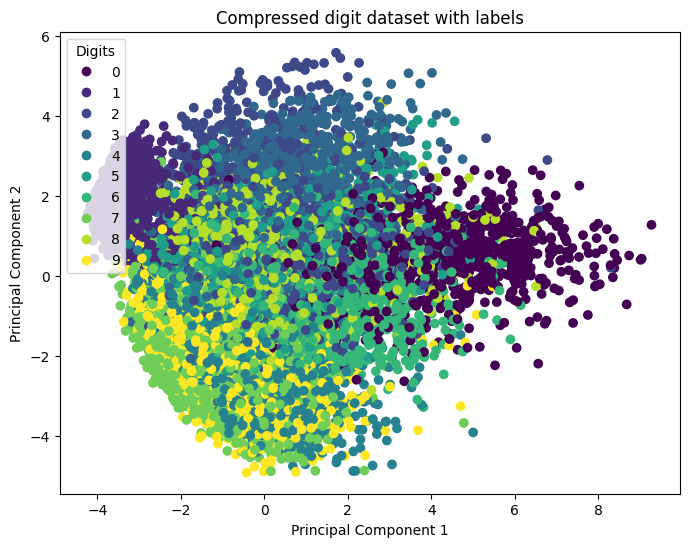

In [2]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.decomposition import PCA

labels_str = ["0", "1", "2", "3", "4", "5", "6", "7", "8", "9"]

# Define data_proj and labels
# Flatten the x_test images for PCA
x_test_flat = x_test.reshape(x_test.shape[0], -1)

# Apply PCA to reduce dimensions to 2 for plotting
pca = PCA(n_components=2)
data_proj = pca.fit_transform(x_test_flat)
labels = y_test # Using y_test as labels

plt.figure(figsize = (8,6))
scatter = plt.scatter(data_proj[:, 0], data_proj[:, 1], c=labels)
plt.legend(handles=scatter.legend_elements()[0], labels=labels_str, loc="upper left", title="Digits")
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title("Compressed digit dataset with labels")
plt.show();

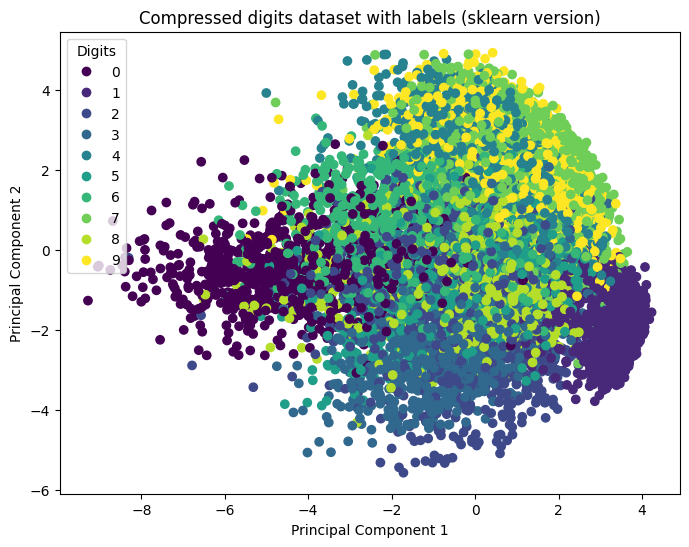

In [ ]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
sklearn_pca = PCA(n_components=2)
data_proj_sklearn = sklearn_pca.fit_transform(x_test_flat)

data_proj_sklearn *= -1
plt.figure(figsize = (8,6))
scatter = plt.scatter(data_proj_sklearn[:, 0], data_proj_sklearn[:, 1], c=labels)
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(handles=scatter.legend_elements()[0], labels=labels_str, loc="upper left", title="Digits")
plt.title("Compressed digits dataset with labels (sklearn version)")
plt.show();